In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


In [13]:
import os
import tensorflow as tf

BASE_DIR = os.path.join("DataSet", "Forect Fire", "Forest Fire_Dataset")

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "val")
TEST_DIR = os.path.join(BASE_DIR, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load subsets directly from their split directories
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Detected Classes:", class_names)
print(f"Total Classes: {num_classes}")

Found 3200 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
Detected Classes: ['fire', 'nofire', 'smoke', 'smokefire']
Total Classes: 4


In [15]:
def create_fire_classifier(num_classes, img_size=(224, 224)):
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(*img_size, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(*img_size, 3))
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)
    return model, base_model

model, base_model = create_fire_classifier(num_classes, IMG_SIZE)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Precision(name="precision"), tf.keras.metrics.Recall(name="recall")]
)

In [16]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    ModelCheckpoint("best_fire_detector.keras", monitor="val_loss", save_best_only=True)
]

epochs = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=callbacks
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 33s 294ms/step - accuracy: 0.7844 - loss: 0.6065 - precision: 0.7969 - recall: 0.7750 - val_accuracy: 0.8438 - val_loss: 0.3941 - val_precision: 0.8548 - val_recall: 0.8388
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 27s 274ms/step - accuracy: 0.8866 - loss: 0.2863 - precision: 0.8913 - recall: 0.8816 - val_accuracy: 0.9112 - val_loss: 0.2280 - val_precision: 0.9178 - val_recall: 0.9075
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 26s 261ms/step - accuracy: 0.9184 - loss: 0.2054 - precision: 0.9225 - recall: 0.9150 - val_accuracy: 0.9262 - val_loss: 0.1965 - val_precision: 0.9296 - val_recall: 0.9250
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 27s 270ms/step - accuracy: 0.9359 - loss: 0.1651 - precision: 0.9375 - recall: 0.9325 - val_accuracy: 0.9237 - val_loss: 0.1919 - val_precision: 0.9306 - val_recall: 0.9212
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 25s 254ms/step - accuracy: 0.9428 - loss: 0.1408 - precision: 0.9451 - recall: 0.9406 - val_accuracy: 0.9250

--- Evaluation on Test Split ---
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 210ms/step - accuracy: 0.7450 - loss: 1.0546 - precision: 0.7444 - recall: 0.7425
Test Loss: 1.0546
Test Compile_metrics: 0.7450

--- Visualizing Predictions from Forest Fire_Tester ---


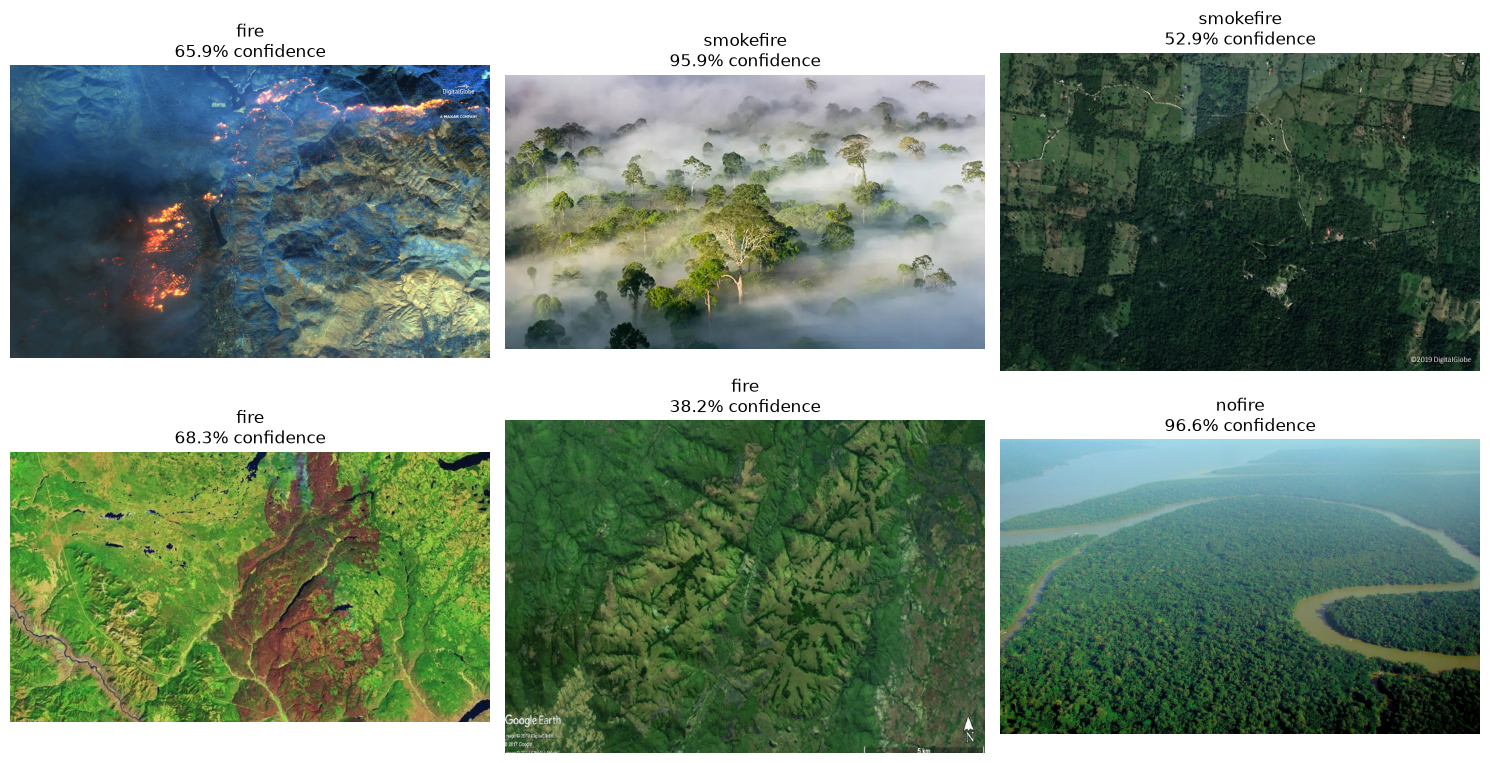

In [17]:
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Quantitative benchmark on the validation/test split
print("--- Evaluation on Test Split ---")
results = model.evaluate(test_ds)
for metric_name, value in zip(model.metrics_names, results):
    print(f"Test {metric_name.capitalize()}: {value:.4f}")

# 2. Inference on the loose images inside Forest Fire_Tester
print("\n--- Visualizing Predictions from Forest Fire_Tester ---")
test_images = glob.glob(os.path.join(TEST_FOLDER_RAW, "*.*"))

plt.figure(figsize=(15, 8))
for i, img_path in enumerate(test_images[:6]):
    bgr_img = cv2.imread(img_path)
    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
    
    resized_img = cv2.resize(rgb_img, IMG_SIZE)
    input_tensor = np.expand_dims(resized_img, axis=0)

    preds = model.predict(input_tensor, verbose=0)[0]
    predicted_idx = np.argmax(preds)
    predicted_label = class_names[predicted_idx]
    confidence = preds[predicted_idx] * 100

    plt.subplot(2, 3, i + 1)
    plt.imshow(rgb_img)
    plt.title(f"{predicted_label}\n{confidence:.1f}% confidence")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
import os

train_path = os.path.join("DataSet", "Forect Fire", "Forest Fire_Dataset", "train")
print("Actual Fire/Normal Classes:", sorted(os.listdir(train_path)))

Actual Fire/Normal Classes: ['fire', 'nofire', 'smoke', 'smokefire']


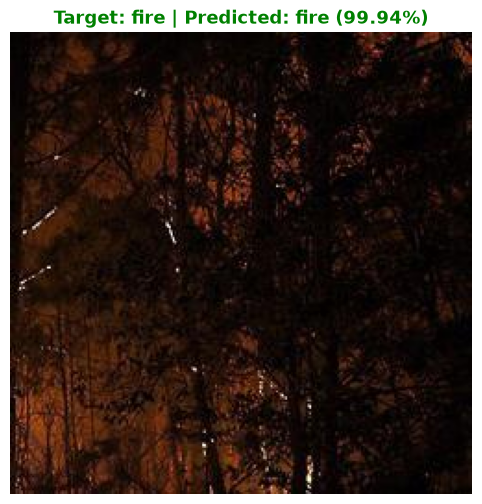

--- Detailed Probability Distribution ---
  fire         :  99.94%
  nofire       :   0.00%
  smoke        :   0.00%
  smokefire    :   0.06%


In [19]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Image path using raw string to prevent backslash escape issues
img_path = r"C:\CNN project\DataSet\Forect Fire\Forest Fire_Dataset\test\fire\fire_test_1002.jpg"

if not os.path.exists(img_path):
    print(f"Error: File not found at {img_path}")
else:
    # 1. Load image and convert color format
    bgr_img = cv2.imread(img_path)
    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
    
    # 2. Resize to model input shape
    resized_img = cv2.resize(rgb_img, (224, 224))
    
    # 3. Format as float32 tensor
    input_tensor = np.expand_dims(resized_img.astype(np.float32), axis=0)
    
    # 4. Predict
    preds = model.predict(input_tensor, verbose=0)[0]
    pred_idx = np.argmax(preds)
    pred_class = class_names[pred_idx]
    pred_conf = preds[pred_idx] * 100
    
    # 5. Display visualization
    plt.figure(figsize=(6, 6))
    plt.imshow(rgb_img)
    plt.title(f"Target: fire | Predicted: {pred_class} ({pred_conf:.2f}%)", 
              fontsize=13, fontweight='bold',
              color='green' if pred_class.lower() == 'fire' else 'red')
    plt.axis("off")
    plt.show()
    
    # 6. Detailed class breakdown
    print("--- Detailed Probability Distribution ---")
    for name, prob in zip(class_names, preds):
        print(f"  {name:12s} : {prob * 100:6.2f}%")


================ Predictions for: fire_test_1002.jpg ================
Expected: fire | Top Prediction: fire (99.94%)
  fire         :  99.94%
  nofire       :   0.00%
  smoke        :   0.00%
  smokefire    :   0.06%

================ Predictions for: nofire_test_1002.jpg ================
Expected: nofire | Top Prediction: nofire (99.99%)
  fire         :   0.00%
  nofire       :  99.99%
  smoke        :   0.00%
  smokefire    :   0.01%


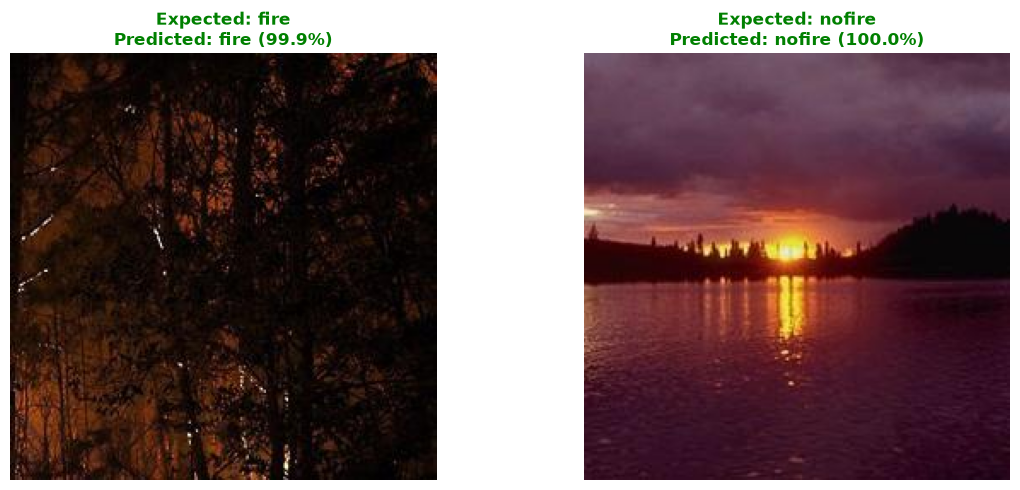

In [20]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

test_samples = [
    {"path": r"C:\CNN project\DataSet\Forect Fire\Forest Fire_Dataset\test\fire\fire_test_1002.jpg", "expected": "fire"},
    {"path": r"C:\CNN project\DataSet\Forect Fire\Forest Fire_Dataset\test\nofire\nofire_test_1002.jpg", "expected": "nofire"}
]

plt.figure(figsize=(12, 5))

for i, sample in enumerate(test_samples):
    img_path = sample["path"]
    expected_label = sample["expected"]
    
    if not os.path.exists(img_path):
        print(f"Error: Could not find {img_path}")
        continue

    # Load and preprocess
    bgr_img = cv2.imread(img_path)
    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
    resized_img = cv2.resize(rgb_img, (224, 224))
    input_tensor = np.expand_dims(resized_img.astype(np.float32), axis=0)

    # Predict
    preds = model.predict(input_tensor, verbose=0)[0]
    pred_idx = np.argmax(preds)
    pred_label = class_names[pred_idx]
    confidence = preds[pred_idx] * 100

    # Plot
    plt.subplot(1, 2, i + 1)
    plt.imshow(rgb_img)
    is_correct = (pred_label.lower() == expected_label.lower())
    title_color = "green" if is_correct else "red"
    plt.title(f"Expected: {expected_label}\nPredicted: {pred_label} ({confidence:.1f}%)", 
              fontsize=12, fontweight='bold', color=title_color)
    plt.axis("off")

    print(f"\n================ Predictions for: {os.path.basename(img_path)} ================")
    print(f"Expected: {expected_label} | Top Prediction: {pred_label} ({confidence:.2f}%)")
    for name, prob in zip(class_names, preds):
        print(f"  {name:12s} : {prob * 100:6.2f}%")

plt.tight_layout()
plt.show()